# Linear System of Equations - Conditioning

In [1]:
import numpy as np
import numpy.linalg as la

# I Conditioning - Motivation

## Conditioning of $2\times2$ matrices


This mini-demo gives you the opportunity to play around with the 2-norm condition number of a $2\times 2$ matrix. 

* What happens if you choose the columns of the matrix to be nearly linearly dependent?
* What happens if you choose the diagonal entries to be very different in magnitude?

In [2]:
la.cond([
         [0.000001, 0.1],
         [0,  1]
         ], 2)

np.float64(1010000.0000000101)

## Numerical experiments

Input has uncertainties:
* Errors due to representation with finite precision
* Error in the sampling  
Once you select	your numerical method, how much error should you expect to see in your output?  
Is your method sensitive to errors (perturbation) in the input?

Let's say, solve for $Ax = b$:  

1) Defining A (here, we will use a random matrix and a Hilbert matrix)  
2) Start with a know exact solution: $x_{true} = \begin{bmatrix} 1, 1, \cdots, 1\end{bmatrix} ^T$ (`np.ones(n)`)  
3) compute $b = A @ x_{true}$  
4) solve $Ax = b$ using your method  
5) compute error: $\|x_{solve} - x_{true}\|$

In [3]:
import numpy.linalg as la
import numpy as np

In [4]:
ndim = np.array([2,3,8,11,14])

Let's perform linear solves for matrices with increasing size "n", for a problem in which we know what the solution would be.

In [5]:
for nd in ndim:
    ## This is the vector 'x' that we want to obtain (the exact one)
    x = np.ones(nd)
    ## Create a matrix with random values between 0 and 1
    A = np.random.rand(nd,nd)
    ## We compute the matrix-vector multiplication 
    ## to find the right-hand side b
    b = A @ x
    ## We now use the linear algebra pack to compute Ax = b and solve for x
    x_solve = la.solve(A,b)
    ## What do we expect? 
    print("------ N =", nd, "----------")
    error = x_solve-x
    print("Norm of error = ", la.norm(error,2)) 

------ N = 2 ----------
Norm of error =  0.0
------ N = 3 ----------
Norm of error =  2.220446049250313e-16
------ N = 8 ----------
Norm of error =  1.354699575657577e-14
------ N = 11 ----------
Norm of error =  2.3702156527071566e-14
------ N = 14 ----------
Norm of error =  4.049332069934613e-14


In [6]:
print(x_solve)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Now we will perform the same computation, but for a special matrix, known as the Hilbert matrix

In [7]:
def Hilbert(n):  
    H = np.zeros((n, n))    
    for i in range(n):        
        for j in range(n):        
            H[i,j] = 1.0/(j+i+1)    
    return H

In [8]:
for nd in ndim:
    ## This is the vector 'x' that we want to obtain (the exact one)
    x = np.ones(nd)
    ## Create the Hilbert matrix
    A = Hilbert(nd)
    ## We compute the matrix-vector multiplication 
    ## to find the right-hand side b
    b = A @ x  
    ## We now use the linear algebra pack to compute Ax = b and solve for x
    x_solve = la.solve(A,b)
    ## What do we expect? 
    print("------ N =", nd, "----------")
    error = x_solve-x
    print("Norm of error = ", la.norm(error,2)) 

------ N = 2 ----------
Norm of error =  5.978733960281817e-16
------ N = 3 ----------
Norm of error =  1.0934428697813141e-15
------ N = 8 ----------
Norm of error =  2.3502166791744056e-07
------ N = 11 ----------
Norm of error =  0.0064628412250969615
------ N = 14 ----------
Norm of error =  13.883571648713605


In [9]:
print(x_solve)

[ 0.99999998  1.00000378  0.99982175  1.00358138  0.96134495  1.25269826
 -0.07167319  4.06675442 -5.03587257  9.18421101 -6.51162457  5.45670181
 -0.54241747  1.23647047]


**What went wrong?**

# II Condition number

## Sensitivity of Solutions of Linear Systems

Suppose we start with a non-singular system of linear equations $Ax = b$.  
We change the right-hand side vector $\mathbf{b}$ (input) by a small amount $\Delta\mathbf{b}$  
How much the solution $\mathbf{x}$ (output) changes, i.e., how large is $\Delta\mathbf{x}$?
$$
\frac{\text{Output Relative error}}{\text{Input Relative error}}
=
\frac{\frac{\|\Delta\mathbf{x}\|}{\|\mathbf{x}\|}}{\frac{\|\Delta\mathbf{b}\|}{\|\mathbf{b}\|}}
=
\frac{\|\Delta\mathbf{x}\|\|\mathbf{b}\|}{\|\Delta\mathbf{b}\|\|\mathbf{x}\|}
$$

$Ax = b$: exact  
$A \hat{x} = \hat{b}$: pert  
$\hat{x} = x + \Delta x, \hat{b} = b + \Delta b$
$A(x + \Delta x) = b + \Delta b \Rightarrow  \Rightarrow \Delta x = A^{-1} \Delta b$

$$
\frac{\text{Output Relative error}}{\text{Input Relative error}}
=
\frac{\|\Delta\mathbf{x}\|\|\mathbf{b}\|}{\|\Delta\mathbf{b}\|\|\mathbf{x}\|}
=
\frac{\|\mathbf{A}^{-1} \Delta \mathbf{b}\|\|\mathbf{b}\|}{\|\Delta\mathbf{b}\|\|\mathbf{x}\|} \\
\\
\leq
\frac{\|\mathbf{A}^{-1}\|\| \Delta \mathbf{b}\|\|\mathbf{b}\|}{\|\Delta\mathbf{b}\|\|\mathbf{x}\|} 
=
\frac{\|\mathbf{A}^{-1}\|\|\mathbf{b}\|}{\|\mathbf{x}\|} 
=
\frac{\|\mathbf{A}^{-1}\|\|\mathbf{A} \mathbf{x}\|}{\|\mathbf{x}\|} \\
\\
\leq
\frac{\|\mathbf{A}^{-1}\|\|\mathbf{A}\|\| \mathbf{x}\|}{\|\mathbf{x}\|}
=
\|\mathbf{A}^{-1}\|\|\mathbf{A}\| \\
\\
\Rightarrow
\boxed{\frac{\text{Output Relative error}}{\text{Input Relative error}} \leq \|\mathbf{A}^{-1}\|\|\mathbf{A}\|}
$$

$$
\frac{\|\Delta\mathbf{x}\|}{\|\mathbf{x}\|} \leq \|\mathbf{A}^{-1}\|\|\mathbf{A}\| \frac{\|\Delta\mathbf{b}\|}{\|\mathbf{b}\|}
$$

We can also add a perturbation to the matrix $A$ (input) by a small amount $E$, such that 
$$
(\mathbf{A} + \mathbf{E})\hat{x} = \mathbf{b}
$$
and in a similar way obtain:
$$
\frac{\|\Delta\mathbf{x}\|}{\|\mathbf{x}\|} \leq \|\mathbf{A}^{-1}\|\|\mathbf{A}\| \frac{\|\mathbf{E}\|}{\|\mathbf{A}\|}
$$

The solution to this linear system is extremely sensitive to small changes in the matrix entries and the right-hand side entries. What is the condition number of the Hilbert matrix?

In [10]:
for nd in ndim:
    ## This is the vector 'x' that we want to obtain (the exact one)
    x = np.ones(nd)
    ## Create the Hilbert matrix
    A = Hilbert(nd)
    ## We compute the matrix-vector multiplication 
    ## to find the right-hand side b
    b = A @ x
    ## We now use the linear algebra pack to compute Ax = b and solve for x
    x_solve = la.solve(A,b)
    ## What do we expect? 
    print("------ N =", nd, "----------")
    error = x_solve-x
    print("Norm of error = ", la.norm(error,2)) 
    print("Condition number = ", la.cond(A,2))

------ N = 2 ----------
Norm of error =  5.978733960281817e-16
Condition number =  19.281470067903985
------ N = 3 ----------
Norm of error =  1.0934428697813141e-15
Condition number =  524.0567775860618
------ N = 8 ----------
Norm of error =  2.3502166791744056e-07
Condition number =  15257576109.216072
------ N = 11 ----------
Norm of error =  0.0064628412250969615
Condition number =  521729711748770.25
------ N = 14 ----------
Norm of error =  13.883571648713605
Condition number =  4.0487006140928083e+17


## Definition and Properties of condition number

The condition number is a measure of sensitivity of solving a linear system of equations to variations in the input.  
The condition number of a matrix $\mathbf{A}$:  
$$
\text{cond}(\mathbf{A}) = \|\mathbf{A}^{-1}\|\|\mathbf{A}\|
$$
Recall that the induced matrix norm is given by
$$
\|\mathbf{A}\|_p = \max_{\|\mathbf{x}\| = 1} \|\mathbf{A}\mathbf{x}\|_p
$$
And since the condition number is relative to a given norm, we should be
precise and for example write $\text{cond}_2(\mathbf{A})$ or $\text{cond}_{\infty}(\mathbf{A})$ 

$$
\frac{\|\Delta\mathbf{x}\|}{\|\mathbf{x}\|} \leq \text{cond}(\mathbf{A}) \frac{\|\Delta\mathbf{b}\|}{\|\mathbf{b}\|}
$$
Small condition numbers mean not a lot of error amplification. Small condition numbers are good!  
But how small?  
1) $\text{cond}(\mathbf{A}) > 0$ since norms are always positive  
2) $\|\mathbf{X}\mathbf{Y}\| \leq \|\mathbf{X}\|\|\mathbf{Y}\|$ by triangular inequality, thereby 
$\text{cond}(\mathbf{A}) = \|\mathbf{A}^{-1}\|\|\mathbf{A}\| \geq \|\mathbf{I}\| = \max_{\|\mathbf{x}\| = 1} \|\mathbf{I}\mathbf{x}\|_p = 1$
$\Rightarrow \boxed{\text{cond}(\mathbf{A}) = \|\mathbf{A}^{-1}\|\|\mathbf{A}\| \geq 1}$  
If $\mathbf{A}^{-1}$ does not exist, then $\text{cond}(\mathbf{A}) = \infty$ (by convention)

What is the 2-norm condition number of an orthogonal matrix $\mathbf{A}$?
$$
\text{cond}(\mathbf{A})_2 
= 
\|\mathbf{A}^{-1}\|_2\|\mathbf{A}\|_2 
=
\|\mathbf{A}^T\|_2\|\mathbf{A}\|_2 
= 
1
$$
That means orthogonal matrices have optimal conditioning.
They are very **well-behaved** in computation.

if $\text{cond}(\mathbf{A})$ is small, then the matrix $\mathbf{A}$ is **well-conditioned**  
if $\text{cond}(\mathbf{A})$ is big, then the matrix $\mathbf{A}$ is **ill-conditioned**

## About condition numbers

1. For any matrix $\mathbf{A}$, $\text{cond}(\mathbf{A}) \geq 1$  

2. For the identity matrix $\mathbf{I}$, $\text{cond}(\mathbf{I}) = 1$  

3. For any matrix $\mathbf{A}$ and a nonzero scalar $\gamma$, $\text{cond}(\gamma \mathbf{A}) = \text{cond}(\mathbf{A})$  

4. For any diagonal matrix $\mathbf{D}$, $\text{cond}(\mathbf{D})_i = \frac{\max{|d_i|}}{\min{|d_i|}}$, for any $i \in \mathbb{N}_+$  

5. The condition number is a measure of how close a matrix is to being singular: a matrix with large condition number is nearly singular, whereas a matrix with a condition number close to 1 is far from being singular

6. The determinant of a matrix is **NOT** a good indicator is a matrix is near singularity 

## III Residual

Our goal is to find the solution $x$ to the linear system of equations $Ax = b$
Let us recall the solution of the perturbed problem
$$
\hat{x} = (x + \Delta x)
$$
which could be the solution of
$A\hat{x} = (b + \Delta b)$, $(A + E)\hat{x} = b$, or $(A + E)\hat{x} = (b + \Delta b)$  
And the error vector as
$$
e = \Delta x = x - \hat{x}
$$
We can write the **residual vector** as
$$
r = b - A\hat{x}
$$

**Residual vector**
(How well the solution satisfies the problem)
$$
r = b - A\hat{x} = \frac{\|r\|}{\|A\|\|x\|}
$$
**Relative error**
(How close the approximated solution is from the exact one)
$$
e = \frac{\|\Delta x\|}{\|x\|}
$$


It is possible to show that the residual satisfies the following inequality:
$$
\frac{\|r\|}{\|A\|\|x\|} \leq c \epsilon_m
$$
Where $c$ is “large” constant when LU/Gaussian elimination is performed without pivoting and “small” with partial pivoting.  

Therefore, Gaussian elimination with partial pivoting yields **small relative residual** regardless of conditioning of the system.

When solving a system of linear equations via LU with partial pivoting, the relative residual is guaranteed to be small!

$$
\|\Delta x\|
=
\|\hat{x} - x\|
=
\|A^{-1}A\hat{x} - A^{-1}b\|
=
\|A^{-1}(A\hat{x} - b)\|
=
\|A^{-1}r\|
\\
\Rightarrow
\frac{\|\Delta\mathbf{x}\|}{\|\mathbf{x}\|} 
=
\frac{\|A^{-1}r\|}{\|\mathbf{x}\|} 
\leq
\frac{\|A^{-1}\|\|r\|}{\|\mathbf{x}\|} 
=
\frac{\|A^{-1}\|\|r\|}{\|\mathbf{x}\|} \frac{\|A\|}{\|A\|}
\\
\Rightarrow
\frac{\|\Delta\mathbf{x}\|}{\|\mathbf{x}\|} 
\leq
\underbrace{\|\mathbf{A}^{-1}\|\|\mathbf{A}\|}_{\text{cond}(\mathbf{A})} \frac{\|r\|}{\|A\|\|x\|}
$$

In [31]:
for nd in ndim:
    ## This is the vector 'x' that we want to obtain (the exact one)
    x = np.ones(nd)
    ## Create the Hilbert matrix
    A = Hilbert(nd)
    ## We compute the matrix-vector multiplication 
    ## to find the right-hand side b
    b = A @ x
    ## We now use the linear algebra pack to compute Ax = b and solve for x
    x_solve = la.solve(A,b)
    ## What do we expect? 
    print("------ N =", nd, "----------")
    error = x_solve-x
    residual = A@x_solve - b
    print("Error norm = ", la.norm(error,2)) 
    print("Residual norm = ", la.norm(residual,2)) 

------ N = 2 ----------
Error norm =  5.978733960281817e-16
Residual norm =  0.0
------ N = 3 ----------
Error norm =  1.0934428697813141e-15
Residual norm =  0.0
------ N = 8 ----------
Error norm =  2.3502166791744056e-07
Residual norm =  5.551115123125783e-16
------ N = 11 ----------
Error norm =  0.0064628412250969615
Residual norm =  3.3306690738754696e-16
------ N = 14 ----------
Error norm =  13.883571648713605
Residual norm =  7.021666937153402e-16


In [12]:
x_solve

array([ 0.99999998,  1.00000378,  0.99982175,  1.00358138,  0.96134495,
        1.25269826, -0.07167319,  4.06675442, -5.03587257,  9.18421101,
       -6.51162457,  5.45670181, -0.54241747,  1.23647047])

## IV Rule of thumb

Suppose we want to find the solution $x$ to the linear system of equations $A \mathbf{x} = \mathbf{b}$ using LU factorization with partial pivoting and backward/forward substitutions.  
Suppose we compute the solution $\hat{x}$.  
If the entries in $A$ and $b$ are accurate to $S$ decimal digits ($e_r = \frac{\|\Delta b\|}{\|b\|} \leq 10^{-S}$),  
and $\text{cond}(\mathbf{A}) = 10^{W}$,  
then the elements of the solution vector $\hat{x}$ will be accurate to about
$$
S - W
$$ 
decimal digits.


In IEEE double precision, $(\epsilon_{mach} \approx 2.2\times 10^{-16})$, which means the entries in $({\bf A})$ and $(\boldsymbol{b})$ are accurate to   
$(\vert\log_{10}(2.2\times 10^{-16})\vert \approx 16)$ decimal digits.

In [13]:
for nd in ndim:
    ## This is the vector 'x' that we want to obtain (the exact one)
    x = np.ones(nd)
    ## Create the Hilbert matrix
    A = Hilbert(nd)
    ## We compute the matrix-vector multiplication 
    ## to find the right-hand side b
    b = A @ x
    ## We now use the linear algebra pack to compute Ax = b and solve for x
    x_solve = la.solve(A,b)
    ## What do we expect? 
    print("------ N =", nd, "----------")
    residual = A@x_solve - b
    print("Residual norm = ", la.norm(residual,2))   
    print("|dx| / |x| < ", la.cond(A,2)*10**(-16))

------ N = 2 ----------
Residual norm =  0.0
|dx| / |x| <  1.9281470067903984e-15
------ N = 3 ----------
Residual norm =  0.0
|dx| / |x| <  5.240567775860618e-14
------ N = 8 ----------
Residual norm =  5.551115123125783e-16
|dx| / |x| <  1.5257576109216072e-06
------ N = 11 ----------
Residual norm =  3.3306690738754696e-16
|dx| / |x| <  0.05217297117487702
------ N = 14 ----------
Residual norm =  7.021666937153402e-16
|dx| / |x| <  40.48700614092808


In [14]:
import numpy as np
import numpy.linalg as la
import scipy.linalg as sla

In [15]:
def lu1(A):
    """
    """
    LU = A.copy()
    
    n = A.shape[0]
    for i in range(1,n):
        l_21 = LU[i:,i-1]
        u_12 = LU[i-1,i:]
        A_22 = LU[i:,i:]
        u_11 = LU[i-1,i-1]
        
        # l_{21} = a_{21} / u_{11}
        l_21 /= u_11
        # A_{22} = LU[] 
        A_22 += -np.outer(l_21, u_12)
        
    return LU

# Try this

$$
Ax = \begin{bmatrix}c&1\\-1&1\end{bmatrix}\begin{bmatrix}x_1\\x_2\end{bmatrix}
=
\begin{bmatrix}b_1\\b_2\end{bmatrix}
$$
with an exact solution of $x_{exact} = \begin{bmatrix}1\\1\end{bmatrix}$  

In [16]:
c = 1e-16
A = np.array([[c, 1.], [-1, 1]])
# xx is the exact solution
xx = np.array([1,1])
b = A.dot(xx)

# Comput the LU
LU = lu1(A)
L = np.tril(LU,-1) + np.eye(2,2)
U = np.triu(LU)

# Solve
# x is the numerical (xhat)
y = sla.solve_triangular(L, b, lower=True)
x = sla.solve_triangular(U, y)

print("Condition number = ", la.cond(A,2))

print("Exact solution = ", xx)

print("Computed solution = ",x)

print("Error = ", la.norm(xx-x))



Condition number =  2.6180339887498953
Exact solution =  [1 1]
Computed solution =  [0. 1.]
Error =  1.0


## Residual

In [17]:
c = 1e-1
A = np.array([[c, 1.], [-1, 1]])
xx = np.array([1,1])
b = A.dot(xx)

# Comput the LU
LU = lu1(A)
L = np.tril(LU,-1) + np.eye(2,2)
U = np.triu(LU)

# Solve
y = sla.solve_triangular(L, b, lower=True)
x = sla.solve_triangular(U, y)


print("Exact solution = ", xx)

print("Computed solution = ",x)

print("Condition number = ", la.cond(A,2))

print("Residual norm = ",la.norm(A@x - b))

print("Error norm = ",la.norm(xx - x))

Exact solution =  [1 1]
Computed solution =  [1. 1.]
Condition number =  2.301949180860181
Residual norm =  8.881784197001252e-16
Error norm =  8.881784197001252e-16


# Rule of Thumb on Conditioning

In [18]:
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt

# print(plt.style.available) # uncomment to print all styles
import seaborn as sns
sns.set(font_scale=2)
plt.rcParams['figure.figsize'] = (8,6.0)
%matplotlib inline

### Let's make a matrix

In [19]:
n = 10
A = np.random.rand(n,n)

delta = 1e-16

A[:,1] = A[:,0] + delta*A[:,1]
print("cond = %g" % np.linalg.cond(A))

cond = 4.06351e+16


### Make a problem we know the answer to:


Let $x={\bf 1}$, then $x$ solves the problem
$$
A x = b
$$
where $b = A {\bf 1}$.

In [20]:
# This is the exact solution
xexact = np.ones((n,))
b = A.dot(xexact)

In [21]:
# This is the approximated solution
xnum = np.linalg.solve(A, b)

Since we are solving with LU with partial pivoting, the residual should be small!

## Residual Versus Error

$$
r = b - A x
$$
whereas
$$
e = x_{exact} - x
$$

In [22]:
xexact

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [23]:
xnum

array([-10.73321238,  12.73321238,   1.        ,   1.        ,
         1.        ,   1.        ,   1.        ,   1.        ,
         1.        ,   1.        ])

In [24]:
r = b - A@xnum
e = xexact - xnum

In [25]:
print("norm of residual = ", la.norm(r))
print("norm of the error = ", la.norm(e))

norm of residual =  4.2826412465193164e-15
norm of the error =  16.59326807189541


The condition number of A is high (ill-conditioned problem), and hence the error bound is also high.

## Let's do a test


We'll do the following steps
1. Make a matrix $A$
2. Find it's smallest eigenvalue $\lambda$, then $A - \lambda I$ would be singular
3. Instead, let's make B = $A - \lambda \cdot c\cdot I$ where c is a parameter in $[0,1]$.  This will make the problem closer and closer to singular.
4. Plot the condition number versus the error.

In [26]:
n = 10
A = np.random.rand(n,n)
A = A.dot(A.T)  # make it symmetric
v, _ = np.linalg.eig(A)
lmbda = np.min(np.abs(v))
I = np.eye(n,n)
print(lmbda)
print(np.linalg.cond(A - lmbda*I))

5.639590389623549e-05
5.821648574406216e+16


In [27]:
x = np.ones((n,))
b = A.dot(x)

cond = []
error = []
clist = 1.0-1.0/np.logspace(0,15,int(100))
clist.sort()
for c in clist:
    B = A - lmbda * c * I
    xnum = np.linalg.solve(B, b)
    cond.append(np.linalg.cond(B))
    error.append(np.linalg.norm(x-xnum))

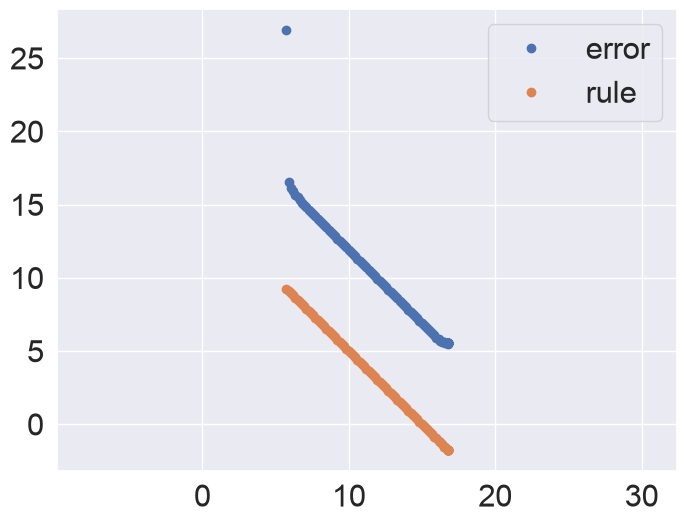

In [28]:
plt.plot(np.log10(cond),15-np.log10(error), 'o', label='error')
plt.plot(np.log10(cond),15-np.log10(cond), 'o', label='rule')
plt.axis('equal')
plt.legend()

In [29]:
import random
lambda1 = random.randint(3,12)
while 1:
    lambda2 = random.randint(5,20)
    if lambda2 != lambda1:
        break

A = np.array([[lambda1,0],[random.randint(-4,4),lambda2]])

In [30]:
A

array([[3, 0],
       [3, 5]])